In [1]:
###INDIRECT IMPACTS FREDDY

In [8]:
#pip install -e ./

Obtaining file:///cluster/project/climate/gespejo
ERROR: file:///cluster/project/climate/gespejo does not appear to be a Python project: neither 'setup.py' nor 'pyproject.toml' found.
Note: you may need to restart the kernel to use updated packages.


In [45]:
from climada_petals.hazard import TCForecast
import logging
import datetime
import os
import numpy as np
import geopandas as gpd
import pickle

In [46]:
### impacts calculated
with open('/cluster/work/climate/gespejo/FREDDY_picklefiles/disrupt_imph2.pkl', 'rb') as file:
    disrupt_imph2 = pickle.load(file)
with open('/cluster/work/climate/gespejo/FREDDY_picklefiles/disrupt_pp1.pkl', 'rb') as file:
    disrupt_pp1 = pickle.load(file)
with open('/cluster/work/climate/gespejo/FREDDY_picklefiles/imph2.pkl', 'rb') as file:
    imph2 = pickle.load(file)
with open('/cluster/work/climate/gespejo/FREDDY_picklefiles/imph1.pkl', 'rb') as file:
    imph1 = pickle.load(file)
with open('/cluster/work/climate/gespejo/FREDDY_picklefiles_cat/imph1_cat.pkl', 'rb') as file:
    imph1_cat = pickle.load(file)
with open('/cluster/work/climate/gespejo/FREDDY_picklefiles/ed2.pkl', 'rb') as file:
    ed2 = pickle.load(file)
with open('/cluster/work/climate/gespejo/FREDDY_picklefiles/rd2.pkl', 'rb') as file:
    rd2 = pickle.load(file)
with open('/cluster/work/climate/gespejo/FREDDY_picklefiles/impp1.pkl', 'rb') as file:
    impp1 = pickle.load(file)
with open('/cluster/work/climate/gespejo/FREDDY_picklefiles/impp2.pkl', 'rb') as file:
    impp2 = pickle.load(file)
with open('/cluster/work/climate/gespejo/FREDDY_picklefiles/rd1_51ens.pkl', 'rb') as file:
    rd1_51ens = pickle.load(file)
with open('/cluster/work/climate/gespejo/FREDDY_picklefiles/rd2_51ens.pkl', 'rb') as file:
    rd2_51ens = pickle.load(file)
with open('/cluster/work/climate/gespejo/FREDDY_picklefiles/rd2_mimpact.pkl', 'rb') as file:
    rd2_mimpact = pickle.load(file)
#with open('/cluster/work/climate/gespejo/FREDDY_picklefiles/impp3.pkl', 'rb') as file:
#    impp3 = pickle.load(file)
with open('/cluster/work/climate/gespejo/FREDDY_picklefiles/impp5.pkl', 'rb') as file:
    impp5 = pickle.load(file)
with open('/cluster/work/climate/gespejo/FREDDY_picklefiles/impp6.pkl', 'rb') as file:
    impp6 = pickle.load(file)
#with open('/cluster/work/climate/gespejo/FREDDY_picklefiles/impp7.pkl', 'rb') as file:
#    impp7 = pickle.load(file)
with open('/cluster/work/climate/gespejo/FREDDY_picklefiles/exp_dict.pkl', 'rb') as file:
    exp_dict = pickle.load(file)

In [47]:
##################### POPULATION 
from climada.entity.exposures.base import Exposures
#from climada.entity.exposures.base import Exposures
#Exposures.from_raster(path_cntry)
gdf_worldpop_MOZ = Exposures.from_raster('/cluster/work/climate/gespejo/data/infrastructure/population/moz_ppp_2020_1km_Aggregated_UNadj.tif')
#(exposure_pp.gdf.value==0).all()
#exposure_pp_MOZ.gdf
gdf_worldpop_MOZ.set_geometry_points()
###roads original
import geopandas as gpd
gdf_roads_MOZ = gpd.read_feather('/cluster/work/climate/gespejo/data/infrastructure/Mozambique_results_MOZ_2023/road')
# Rename the 'value' column to 'people'
## This one I should do anyway for the nex 
gdf_worldpop_MOZ.gdf.rename(columns={'value': 'people'}, inplace=True)

In [48]:
###SUBNATIONAL DIVISION 
import geopandas as gpd
geofile_MOZ = '/cluster/work/climate/gespejo/data/infrastructure/Mozambique_results_MOZ/gadm41_MOZ_shp/gadm41_MOZ_1.shp'
gadm_MOZ = gpd.read_file(geofile_MOZ)
from climada_petals.hazard.IMP_TRACKFORECAST import convert_to_geodf
gadm_MOZ_gdf = convert_to_geodf(gadm_MOZ, ['NAME_1', 'geometry'])

In [49]:
from climada_petals.hazard.IMP_Indirect import (
    get_disrupted_exposures_and_ensemble,
    get_disrupted_road,
    add_geometry_to_disrupted_roads,
    add_population_and_region_to_disrupted,
    cal_nearestpop_to_infrastructure,
    calc_pp_byroaddisrup_5ens,
    assign_province_to_roads)

In [53]:
def calculate_direct_and_indirect_impacts(
    imph2, imps2, impp1, rd2_mimpact,
    gdf_roads_MOZ,
    gdf_worldpop_MOZ, gadm_MOZ_gdf, gadm_MOZ,
    threshold: float = 0.20,
    min_members: int = 5,
    mode: str = "above",
    road_radius_km: float = 2.0,
):
    """
    Returns:
      imph2_impp1, ed2_impp1, impp1_disrupted, rd2_disrupted_impp1
    Other helpers assumed available in your codebase:
      - get_disrupted_road
      - add_geometry_to_disrupted_roads
      - cal_nearestpop_to_infrastructure
      - calc_pp_byroaddisrup_5ens
      - assign_province_to_roads
    """

    # 1. Disrupted hospitals / schools
    disrupted_hospitals = get_disrupted_exposures_and_ensemble(
        imph2, threshold=threshold, min_members=min_members, mode=mode
    )
    disrupted_schools = get_disrupted_exposures_and_ensemble(
        imps2, threshold=threshold, min_members=min_members, mode=mode
    )

    # 2. Disrupted infrastructure (wind, etc.)
    impp1_disrupted = get_disrupted_exposures_and_ensemble(
        impp1, threshold=threshold, min_members=min_members, mode=mode
    )
    if any(df is not None and not getattr(df, "empty", True) for df in impp1_disrupted.values()):
        impp1_disrupted = add_population_and_region_to_disrupted(
            impp1_disrupted, gdf_worldpop_MOZ.gdf if hasattr(gdf_worldpop_MOZ, "gdf") else gdf_worldpop_MOZ, gadm_MOZ_gdf
        )
    else:
        print(f"SKIPPED impp1: no disrupted exposures at threshold={threshold}, min_members={min_members}")

    # 3. Disrupted roads
    rd2_disrupted = get_disrupted_road(
        rd2_mimpact, threshold=threshold, min_members=min_members, mode=mode
    )
    if any(df is not None and not getattr(df, "empty", True) for df in rd2_disrupted.values()):
        rd2_disrupted = add_geometry_to_disrupted_roads(rd2_disrupted, gdf_roads_MOZ)
    else:
        print(f"SKIPPED roads: no disrupted roads at threshold={threshold}, min_members={min_members}")

    # 4. Indirect impacts
    imph2_impp1 = cal_nearestpop_to_infrastructure(disrupted_hospitals, impp1_disrupted)
    ed2_impp1   = cal_nearestpop_to_infrastructure(disrupted_schools,  impp1_disrupted)
    rd2_disrupted_impp1 = calc_pp_byroaddisrup_5ens(
        rd2_disrupted, impp1_disrupted, radius_km=road_radius_km
    )
    rd2_disrupted_impp1 = assign_province_to_roads(rd2_disrupted_impp1, gadm_MOZ)

    return imph2_impp1, ed2_impp1, impp1_disrupted, rd2_disrupted_impp1

In [54]:
imph2_impp1_tsd020, ed2_impp1_tsd020, impp1_disrupted_tsd020, rd2_disrupted_impp1_tsd020 = calculate_direct_and_indirect_impacts(
    imph2, ed2, impp1, rd2_mimpact,
    gdf_roads_MOZ, gdf_worldpop_MOZ, gadm_MOZ_gdf, gadm_MOZ,
    threshold=0.20, min_members=5
)


 Starting nearest population match for 6 lead times...

  Processing: imph2_MOZ_new_FREDDY_20230306120000 | impp1_MOZ_FREDDY_20230306120000
  SUCCESS: Population + NAME_1 assigned to imph2_MOZ_new_FREDDY_20230306120000

  Processing: imph2_MOZ_new_FREDDY_20230307120000 | impp1_MOZ_FREDDY_20230307120000
  SUCCESS: Population + NAME_1 assigned to imph2_MOZ_new_FREDDY_20230307120000

  Processing: imph2_MOZ_new_FREDDY_20230308120000 | impp1_MOZ_FREDDY_20230308120000
  SUCCESS: Population + NAME_1 assigned to imph2_MOZ_new_FREDDY_20230308120000

  Processing: imph2_MOZ_new_FREDDY_20230309120000 | impp1_MOZ_FREDDY_20230309120000
  SUCCESS: Population + NAME_1 assigned to imph2_MOZ_new_FREDDY_20230309120000

  Processing: imph2_MOZ_new_FREDDY_20230310120000 | impp1_MOZ_FREDDY_20230310120000
  SUCCESS: Population + NAME_1 assigned to imph2_MOZ_new_FREDDY_20230310120000

  Processing: imph2_MOZ_new_FREDDY_20230311120000 | impp1_MOZ_FREDDY_20230311120000
  SUCCESS: Population + NAME_1 assigned

In [55]:
# Save each dictionary separately to the specified directory
import pickle

# Define the directory where you want to save the files
save_dir_pickle = '/cluster/work/climate/gespejo/FREDDY_picklefiles/'
with open(save_dir_pickle + 'imph2_impp1_tsd020.pkl', 'wb') as file:
    pickle.dump(imph2_impp1_tsd020, file)
with open(save_dir_pickle + 'ed2_impp1_tsd020.pkl', 'wb') as file:
    pickle.dump(ed2_impp1_tsd020, file)
with open(save_dir_pickle + 'impp1_disrupted_tsd020.pkl', 'wb') as file:
    pickle.dump(impp1_disrupted_tsd020, file)
with open(save_dir_pickle + 'rd2_disrupted_impp1_tsd020.pkl', 'wb') as file:
    pickle.dump(rd2_disrupted_impp1_tsd020, file)

In [56]:
imph2_impp1_tsd010, ed2_impp1_tsd010, impp1_disrupted_tsd010, rd2_disrupted_impp1_tsd010 = calculate_direct_and_indirect_impacts(
    imph2, ed2, impp1, rd2_mimpact,
    gdf_roads_MOZ, gdf_worldpop_MOZ, gadm_MOZ_gdf, gadm_MOZ,
    threshold=0.10, min_members=5
)


 Starting nearest population match for 6 lead times...

  Processing: imph2_MOZ_new_FREDDY_20230306120000 | impp1_MOZ_FREDDY_20230306120000
  SUCCESS: Population + NAME_1 assigned to imph2_MOZ_new_FREDDY_20230306120000

  Processing: imph2_MOZ_new_FREDDY_20230307120000 | impp1_MOZ_FREDDY_20230307120000
  SUCCESS: Population + NAME_1 assigned to imph2_MOZ_new_FREDDY_20230307120000

  Processing: imph2_MOZ_new_FREDDY_20230308120000 | impp1_MOZ_FREDDY_20230308120000
  SUCCESS: Population + NAME_1 assigned to imph2_MOZ_new_FREDDY_20230308120000

  Processing: imph2_MOZ_new_FREDDY_20230309120000 | impp1_MOZ_FREDDY_20230309120000
  SUCCESS: Population + NAME_1 assigned to imph2_MOZ_new_FREDDY_20230309120000

  Processing: imph2_MOZ_new_FREDDY_20230310120000 | impp1_MOZ_FREDDY_20230310120000
  SUCCESS: Population + NAME_1 assigned to imph2_MOZ_new_FREDDY_20230310120000

  Processing: imph2_MOZ_new_FREDDY_20230311120000 | impp1_MOZ_FREDDY_20230311120000
  SUCCESS: Population + NAME_1 assigned

In [57]:
# Save each dictionary separately to the specified directory
import pickle

# Define the directory where you want to save the files
save_dir_pickle = '/cluster/work/climate/gespejo/FREDDY_picklefiles/'
with open(save_dir_pickle + 'imph2_impp1_tsd010.pkl', 'wb') as file:
    pickle.dump(imph2_impp1_tsd010, file)
with open(save_dir_pickle + 'ed2_impp1_tsd010.pkl', 'wb') as file:
    pickle.dump(ed2_impp1_tsd010, file)
with open(save_dir_pickle + 'impp1_disrupted_tsd010.pkl', 'wb') as file:
    pickle.dump(impp1_disrupted_tsd010, file)
with open(save_dir_pickle + 'rd2_disrupted_impp1_tsd010.pkl', 'wb') as file:
    pickle.dump(rd2_disrupted_impp1_tsd010, file)

In [58]:
imph2_impp1_tsd050, ed2_impp1_tsd050, impp1_disrupted_tsd050, rd2_disrupted_impp1_tsd050 = calculate_direct_and_indirect_impacts(
    imph2, ed2, impp1, rd2_mimpact,
    gdf_roads_MOZ, gdf_worldpop_MOZ, gadm_MOZ_gdf, gadm_MOZ,
    threshold=0.50, min_members=5
)

SKIPPED roads: no disrupted roads at threshold=0.5, min_members=5

 Starting nearest population match for 6 lead times...

  Processing: imph2_MOZ_new_FREDDY_20230306120000 | impp1_MOZ_FREDDY_20230306120000
  SKIPPED: No hospitals in imph2_MOZ_new_FREDDY_20230306120000

  Processing: imph2_MOZ_new_FREDDY_20230307120000 | impp1_MOZ_FREDDY_20230307120000
  SKIPPED: No hospitals in imph2_MOZ_new_FREDDY_20230307120000

  Processing: imph2_MOZ_new_FREDDY_20230308120000 | impp1_MOZ_FREDDY_20230308120000
  SKIPPED: No hospitals in imph2_MOZ_new_FREDDY_20230308120000

  Processing: imph2_MOZ_new_FREDDY_20230309120000 | impp1_MOZ_FREDDY_20230309120000
  SKIPPED: No hospitals in imph2_MOZ_new_FREDDY_20230309120000

  Processing: imph2_MOZ_new_FREDDY_20230310120000 | impp1_MOZ_FREDDY_20230310120000
  SKIPPED: No hospitals in imph2_MOZ_new_FREDDY_20230310120000

  Processing: imph2_MOZ_new_FREDDY_20230311120000 | impp1_MOZ_FREDDY_20230311120000
  SKIPPED: No hospitals in imph2_MOZ_new_FREDDY_20230

In [76]:
rd2_disrupted_impp1_tsd050

{}

In [59]:
# Save each dictionary separately to the specified directory
import pickle

# Define the directory where you want to save the files
save_dir_pickle = '/cluster/work/climate/gespejo/FREDDY_picklefiles/'
with open(save_dir_pickle + 'imph2_impp1_tsd050.pkl', 'wb') as file:
    pickle.dump(imph2_impp1_tsd050, file)
with open(save_dir_pickle + 'ed2_impp1_tsd050.pkl', 'wb') as file:
    pickle.dump(ed2_impp1_tsd050, file)
with open(save_dir_pickle + 'impp1_disrupted_tsd050.pkl', 'wb') as file:
    pickle.dump(impp1_disrupted_tsd050, file)
with open(save_dir_pickle + 'rd2_disrupted_impp1_tsd050.pkl', 'wb') as file:
    pickle.dump(rd2_disrupted_impp1_tsd050, file)

In [60]:
imph2_impp1_ens15, ed2_impp1_ens15, impp1_disrupted_ens15, rd2_disrupted_impp1_ens15 = calculate_direct_and_indirect_impacts(
    imph2, ed2, impp1, rd2_mimpact,
    gdf_roads_MOZ, gdf_worldpop_MOZ, gadm_MOZ_gdf, gadm_MOZ,
    threshold=0.20, min_members=15
)


 Starting nearest population match for 6 lead times...

  Processing: imph2_MOZ_new_FREDDY_20230306120000 | impp1_MOZ_FREDDY_20230306120000
  SUCCESS: Population + NAME_1 assigned to imph2_MOZ_new_FREDDY_20230306120000

  Processing: imph2_MOZ_new_FREDDY_20230307120000 | impp1_MOZ_FREDDY_20230307120000
  SUCCESS: Population + NAME_1 assigned to imph2_MOZ_new_FREDDY_20230307120000

  Processing: imph2_MOZ_new_FREDDY_20230308120000 | impp1_MOZ_FREDDY_20230308120000
  SUCCESS: Population + NAME_1 assigned to imph2_MOZ_new_FREDDY_20230308120000

  Processing: imph2_MOZ_new_FREDDY_20230309120000 | impp1_MOZ_FREDDY_20230309120000
  SUCCESS: Population + NAME_1 assigned to imph2_MOZ_new_FREDDY_20230309120000

  Processing: imph2_MOZ_new_FREDDY_20230310120000 | impp1_MOZ_FREDDY_20230310120000
  SUCCESS: Population + NAME_1 assigned to imph2_MOZ_new_FREDDY_20230310120000

  Processing: imph2_MOZ_new_FREDDY_20230311120000 | impp1_MOZ_FREDDY_20230311120000
  SUCCESS: Population + NAME_1 assigned

In [61]:
# Save each dictionary separately to the specified directory
import pickle

# Define the directory where you want to save the files
save_dir_pickle = '/cluster/work/climate/gespejo/FREDDY_picklefiles/'
with open(save_dir_pickle + 'imph2_impp1_ens15.pkl', 'wb') as file:
    pickle.dump(imph2_impp1_ens15, file)
with open(save_dir_pickle + 'ed2_impp1_ens15.pkl', 'wb') as file:
    pickle.dump(ed2_impp1_ens15, file)
with open(save_dir_pickle + 'impp1_disrupted_ens15.pkl', 'wb') as file:
    pickle.dump(impp1_disrupted_ens15, file)
with open(save_dir_pickle + 'rd2_disrupted_impp1_ens15.pkl', 'wb') as file:
    pickle.dump(rd2_disrupted_impp1_ens15, file)

In [62]:
imph2_impp1_ens25, ed2_impp1_ens25, impp1_disrupted_ens25, rd2_disrupted_impp1_ens25 = calculate_direct_and_indirect_impacts(
    imph2, ed2, impp1, rd2_mimpact,
    gdf_roads_MOZ, gdf_worldpop_MOZ, gadm_MOZ_gdf, gadm_MOZ,
    threshold=0.20, min_members=25
)


 Starting nearest population match for 6 lead times...

  Processing: imph2_MOZ_new_FREDDY_20230306120000 | impp1_MOZ_FREDDY_20230306120000
  SKIPPED: No population data in impp1_MOZ_FREDDY_20230306120000

  Processing: imph2_MOZ_new_FREDDY_20230307120000 | impp1_MOZ_FREDDY_20230307120000
  SKIPPED: No population data in impp1_MOZ_FREDDY_20230307120000

  Processing: imph2_MOZ_new_FREDDY_20230308120000 | impp1_MOZ_FREDDY_20230308120000
  SUCCESS: Population + NAME_1 assigned to imph2_MOZ_new_FREDDY_20230308120000

  Processing: imph2_MOZ_new_FREDDY_20230309120000 | impp1_MOZ_FREDDY_20230309120000
  SUCCESS: Population + NAME_1 assigned to imph2_MOZ_new_FREDDY_20230309120000

  Processing: imph2_MOZ_new_FREDDY_20230310120000 | impp1_MOZ_FREDDY_20230310120000
  SUCCESS: Population + NAME_1 assigned to imph2_MOZ_new_FREDDY_20230310120000

  Processing: imph2_MOZ_new_FREDDY_20230311120000 | impp1_MOZ_FREDDY_20230311120000
  SKIPPED: No population data in impp1_MOZ_FREDDY_20230311120000

 

In [63]:
# Save each dictionary separately to the specified directory
import pickle

# Define the directory where you want to save the files
save_dir_pickle = '/cluster/work/climate/gespejo/FREDDY_picklefiles/'
with open(save_dir_pickle + 'imph2_impp1_ens25.pkl', 'wb') as file:
    pickle.dump(imph2_impp1_ens25, file)
with open(save_dir_pickle + 'ed2_impp1_ens25.pkl', 'wb') as file:
    pickle.dump(ed2_impp1_ens25, file)
with open(save_dir_pickle + 'impp1_disrupted_ens25.pkl', 'wb') as file:
    pickle.dump(impp1_disrupted_ens25, file)
with open(save_dir_pickle + 'rd2_disrupted_impp1_ens25.pkl', 'wb') as file:
    pickle.dump(rd2_disrupted_impp1_ens25, file)

In [64]:
imph2_impp1_ens35, ed2_impp1_ens35, impp1_disrupted_ens35, rd2_disrupted_impp1_ens35 = calculate_direct_and_indirect_impacts(
    imph2, ed2, impp1, rd2_mimpact,
    gdf_roads_MOZ, gdf_worldpop_MOZ, gadm_MOZ_gdf, gadm_MOZ,
    threshold=0.20, min_members=35
)


 Starting nearest population match for 6 lead times...

  Processing: imph2_MOZ_new_FREDDY_20230306120000 | impp1_MOZ_FREDDY_20230306120000
  SKIPPED: No hospitals in imph2_MOZ_new_FREDDY_20230306120000

  Processing: imph2_MOZ_new_FREDDY_20230307120000 | impp1_MOZ_FREDDY_20230307120000
  SKIPPED: No hospitals in imph2_MOZ_new_FREDDY_20230307120000

  Processing: imph2_MOZ_new_FREDDY_20230308120000 | impp1_MOZ_FREDDY_20230308120000
  SKIPPED: No hospitals in imph2_MOZ_new_FREDDY_20230308120000

  Processing: imph2_MOZ_new_FREDDY_20230309120000 | impp1_MOZ_FREDDY_20230309120000
  SKIPPED: No population data in impp1_MOZ_FREDDY_20230309120000

  Processing: imph2_MOZ_new_FREDDY_20230310120000 | impp1_MOZ_FREDDY_20230310120000
  SUCCESS: Population + NAME_1 assigned to imph2_MOZ_new_FREDDY_20230310120000

  Processing: imph2_MOZ_new_FREDDY_20230311120000 | impp1_MOZ_FREDDY_20230311120000
  SKIPPED: No population data in impp1_MOZ_FREDDY_20230311120000

 All processing complete.

 Startin

In [65]:
# Save each dictionary separately to the specified directory
import pickle

# Define the directory where you want to save the files
save_dir_pickle = '/cluster/work/climate/gespejo/FREDDY_picklefiles/'
with open(save_dir_pickle + 'imph2_impp1_ens35.pkl', 'wb') as file:
    pickle.dump(imph2_impp1_ens35, file)
with open(save_dir_pickle + 'ed2_impp1_ens35.pkl', 'wb') as file:
    pickle.dump(ed2_impp1_ens35, file)
with open(save_dir_pickle + 'impp1_disrupted_ens35.pkl', 'wb') as file:
    pickle.dump(impp1_disrupted_ens35, file)
with open(save_dir_pickle + 'rd2_disrupted_impp1_ens35.pkl', 'wb') as file:
    pickle.dump(rd2_disrupted_impp1_ens35, file)

In [66]:
imph2_impp1_ens45, ed2_impp1_ens45, impp1_disrupted_ens45, rd2_disrupted_impp1_ens45 = calculate_direct_and_indirect_impacts(
    imph2, ed2, impp1, rd2_mimpact,
    gdf_roads_MOZ, gdf_worldpop_MOZ, gadm_MOZ_gdf, gadm_MOZ,
    threshold=0.20, min_members=45
)


 Starting nearest population match for 6 lead times...

  Processing: imph2_MOZ_new_FREDDY_20230306120000 | impp1_MOZ_FREDDY_20230306120000
  SKIPPED: No hospitals in imph2_MOZ_new_FREDDY_20230306120000

  Processing: imph2_MOZ_new_FREDDY_20230307120000 | impp1_MOZ_FREDDY_20230307120000
  SKIPPED: No hospitals in imph2_MOZ_new_FREDDY_20230307120000

  Processing: imph2_MOZ_new_FREDDY_20230308120000 | impp1_MOZ_FREDDY_20230308120000
  SKIPPED: No hospitals in imph2_MOZ_new_FREDDY_20230308120000

  Processing: imph2_MOZ_new_FREDDY_20230309120000 | impp1_MOZ_FREDDY_20230309120000
  SKIPPED: No population data in impp1_MOZ_FREDDY_20230309120000

  Processing: imph2_MOZ_new_FREDDY_20230310120000 | impp1_MOZ_FREDDY_20230310120000
  SUCCESS: Population + NAME_1 assigned to imph2_MOZ_new_FREDDY_20230310120000

  Processing: imph2_MOZ_new_FREDDY_20230311120000 | impp1_MOZ_FREDDY_20230311120000
  SKIPPED: No population data in impp1_MOZ_FREDDY_20230311120000

 All processing complete.

 Startin

In [67]:
# Save each dictionary separately to the specified directory
import pickle

# Define the directory where you want to save the files
save_dir_pickle = '/cluster/work/climate/gespejo/FREDDY_picklefiles/'
with open(save_dir_pickle + 'imph2_impp1_ens45.pkl', 'wb') as file:
    pickle.dump(imph2_impp1_ens45, file)
with open(save_dir_pickle + 'ed2_impp1_ens45.pkl', 'wb') as file:
    pickle.dump(ed2_impp1_ens45, file)
with open(save_dir_pickle + 'impp1_disrupted_ens45.pkl', 'wb') as file:
    pickle.dump(impp1_disrupted_ens45, file)
with open(save_dir_pickle + 'rd2_disrupted_impp1_ens45.pkl', 'wb') as file:
    pickle.dump(rd2_disrupted_impp1_ens45, file)

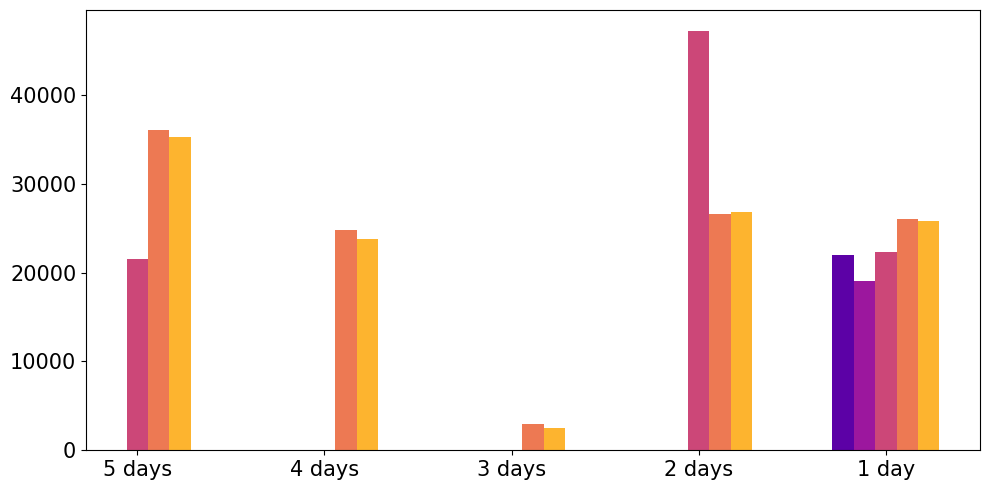

In [112]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ==== choose pairing (Hospitals here). Swap dicts for Schools/Roads if needed ====
scenarios = {
    "Tsd=0.20,ens≥45": imph2_impp1_ens45,
    "Tsd=0.20,ens≥35": imph2_impp1_ens35,
    "Tsd=0.20,ens≥25": imph2_impp1_ens25,   # <- fixed label
    "Tsd=0.20,ens≥15": imph2_impp1_ens15,
    "Tsd=0.10, ens≥5": imph2_impp1_tsd010,
    "Base: Tsd=0.20, ens≥5": imph2_impp1_tsd020,
    "Tsd=0.50, ens≥5": imph2_impp1_tsd050,  # often zero; bars will be skipped
}

def _day_from_key(k):
    m = re.search(r'(\d{14})', str(k))
    return pd.to_datetime(m.group(1), format="%Y%m%d%H%M%S", utc=True).date() if m else None

def _sum_pp_for_day(d, day, col="pp_affected", zero_if_missing=True):
    tot, found = 0.0, False
    for k, gdf in d.items():
        if _day_from_key(k) != day:
            continue
        found = True
        if gdf is not None and hasattr(gdf, "empty") and (not gdf.empty) and (col in gdf.columns):
            tot += float(pd.to_numeric(gdf[col], errors="coerce").fillna(0).sum())
    if not found and zero_if_missing:
        return 0.0
    return (np.nan if not found else tot)

# 1) Collect all unique days across scenarios (chronological)
days_all = sorted({
    _day_from_key(k)
    for d in scenarios.values() for k in d.keys()
    if _day_from_key(k) is not None
})

# 2) Use only the first N-1 days (drop the last day). Expecting 5 days remaining.
days = days_all[:-1]

# 3) Build a table (rows=days, cols=scenarios) of totals
vals = pd.DataFrame(index=days, columns=list(scenarios.keys()), dtype=float)
for lbl, d in scenarios.items():
    for day in days:
        vals.loc[day, lbl] = _sum_pp_for_day(d, day, zero_if_missing=True)

# 4) Plot grouped bars, skipping zeros (and NaNs) — PASTEL COLORS
X = np.arange(len(days))
S = len(vals.columns)
W = 0.8 / S  # bar width per scenario

fig, ax = plt.subplots(figsize=(10, 5))

# pastel palette (try 'Pastel2' if you prefer)
cmap = plt.get_cmap('plasma', S)
colors = [cmap(i) for i in range(S)]

for j, lbl in enumerate(vals.columns):
    y = vals[lbl].to_numpy()
    pos = X + j*W - 0.4 + W/2
    mask = ~np.isnan(y) & (y > 0)   # <-- skip 0 or NaN
    ax.bar(
        pos[mask], y[mask], width=W,
        label=lbl,
        color=colors[j],          # pastel fill
        edgecolor='none',         # slightly darker edge for contrast
        linewidth=0.8
    )

ax.set_xticks(X)

# pretty labels: 5→1 days if we have 5 days, else show actual dates
if len(days) == 5:
    ax.set_xticklabels(["5 days", "4 days", "3 days", "2 days", "1 day"], rotation=0, fontsize=15)
else:
    ax.set_xticklabels([str(d) for d in days], rotation=0,fontsize=15)
ax.tick_params(axis='y', labelsize=15)
#ax.set_xlabel("Lead time / Day")
#ax.set_ylabel("People affected (sum per day)")
#ax.set_title("Sensitivity: sum of pp_affected per day (grouped bars; zeros omitted)")
ax.grid(axis="y", alpha=0)
#ax.legend(ncols=2, fontsize=9, frameon=False)
plt.tight_layout()
fig.savefig("/cluster/home/gespejo/MOZ_struc_plots_Freddy/sensitivity_ind_ppaffected_hospitals.png",
             dpi=2000, bbox_inches='tight')
plt.show()

In [ ]:
## Shools 

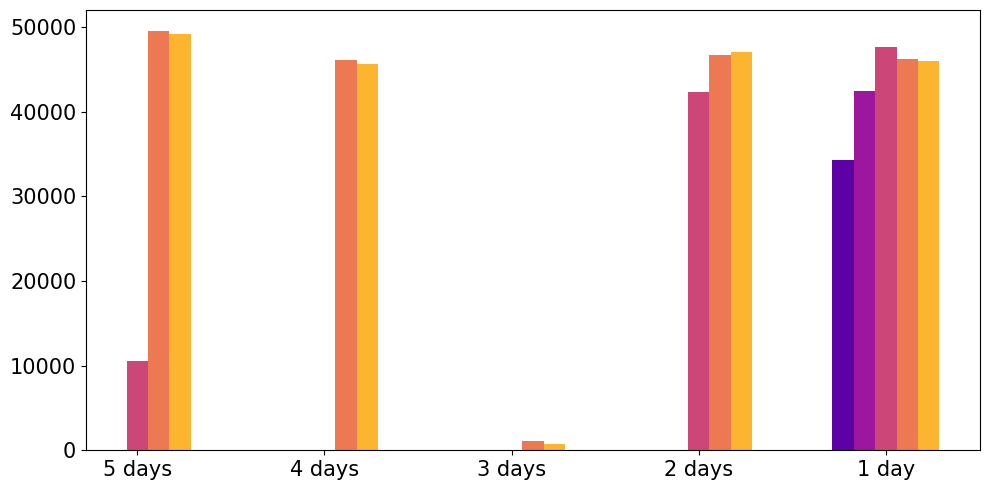

In [113]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ==== choose pairing (Hospitals here). Swap dicts for Schools/Roads if needed ====
scenarios = {
    "Tsd=0.20,ens≥45": ed2_impp1_ens45,
    "Tsd=0.20,ens≥35": ed2_impp1_ens35,
    "Tsd=0.20,ens≥25": ed2_impp1_ens25,   # <- fixed label
    "Tsd=0.20,ens≥15": ed2_impp1_ens15,
    "Tsd=0.10, ens≥5": ed2_impp1_tsd010,
    "Base: Tsd=0.20, ens≥5": ed2_impp1_tsd020,
    "Tsd=0.50, ens≥5": ed2_impp1_tsd050,  # often zero; bars will be skipped
}

def _day_from_key(k):
    m = re.search(r'(\d{14})', str(k))
    return pd.to_datetime(m.group(1), format="%Y%m%d%H%M%S", utc=True).date() if m else None

def _sum_pp_for_day(d, day, col="pp_affected", zero_if_missing=True):
    tot, found = 0.0, False
    for k, gdf in d.items():
        if _day_from_key(k) != day:
            continue
        found = True
        if gdf is not None and hasattr(gdf, "empty") and (not gdf.empty) and (col in gdf.columns):
            tot += float(pd.to_numeric(gdf[col], errors="coerce").fillna(0).sum())
    if not found and zero_if_missing:
        return 0.0
    return (np.nan if not found else tot)

# 1) Collect all unique days across scenarios (chronological)
days_all = sorted({
    _day_from_key(k)
    for d in scenarios.values() for k in d.keys()
    if _day_from_key(k) is not None
})

# 2) Use only the first N-1 days (drop the last day). Expecting 5 days remaining.
days = days_all[:-1]

# 3) Build a table (rows=days, cols=scenarios) of totals
vals = pd.DataFrame(index=days, columns=list(scenarios.keys()), dtype=float)
for lbl, d in scenarios.items():
    for day in days:
        vals.loc[day, lbl] = _sum_pp_for_day(d, day, zero_if_missing=True)

# 4) Plot grouped bars, skipping zeros (and NaNs) — PASTEL COLORS
X = np.arange(len(days))
S = len(vals.columns)
W = 0.8 / S  # bar width per scenario

fig, ax = plt.subplots(figsize=(10, 5))

# pastel palette (try 'Pastel2' if you prefer)
cmap = plt.get_cmap('plasma', S)
colors = [cmap(i) for i in range(S)]

for j, lbl in enumerate(vals.columns):
    y = vals[lbl].to_numpy()
    pos = X + j*W - 0.4 + W/2
    mask = ~np.isnan(y) & (y > 0)   # <-- skip 0 or NaN
    ax.bar(
        pos[mask], y[mask], width=W,
        label=lbl,
        color=colors[j],          # pastel fill
        edgecolor='none',         # slightly darker edge for contrast
        linewidth=0.8
    )

ax.set_xticks(X)

# pretty labels: 5→1 days if we have 5 days, else show actual dates
if len(days) == 5:
    ax.set_xticklabels(["5 days", "4 days", "3 days", "2 days", "1 day"], rotation=0, fontsize=15)
else:
    ax.set_xticklabels([str(d) for d in days], rotation=0,fontsize=15)
ax.tick_params(axis='y', labelsize=15)
#ax.set_xlabel("Lead time / Day")
#ax.set_ylabel("People affected (sum per day)")
#ax.set_title("Sensitivity: sum of pp_affected per day (grouped bars; zeros omitted)")
ax.grid(axis="y", alpha=0)
#ax.legend(ncols=2, fontsize=9, frameon=False)
plt.tight_layout()
fig.savefig("/cluster/home/gespejo/MOZ_struc_plots_Freddy/sensitivity_ind_ppaffected_schools.png",
             dpi=2000, bbox_inches='tight')
plt.show()

In [ ]:
# Roads 

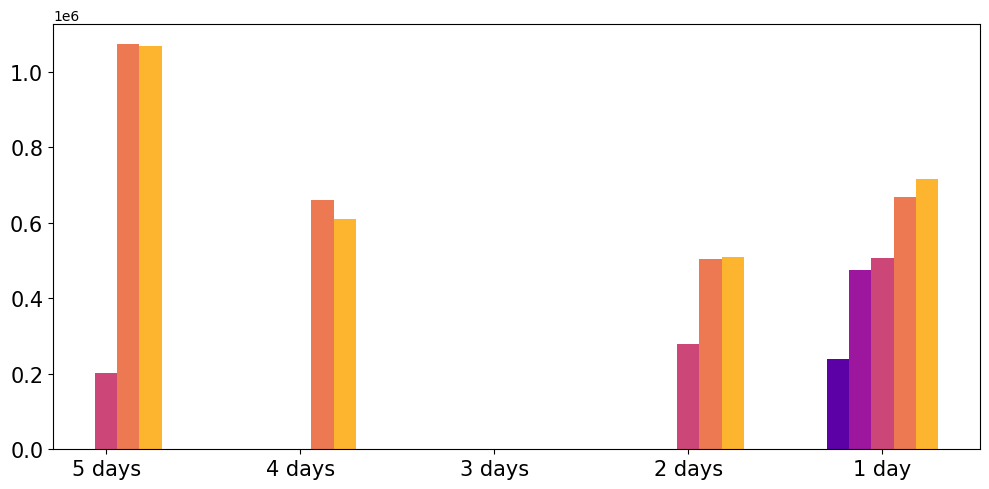

In [116]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ==== choose pairing (Hospitals here). Swap dicts for Schools/Roads if needed ====
scenarios = {
    "Tsd=0.20,ens≥45": rd2_disrupted_impp1_ens45,
    "Tsd=0.20,ens≥35": rd2_disrupted_impp1_ens35,
    "Tsd=0.20,ens≥25": rd2_disrupted_impp1_ens25,   # <- fixed label
    "Tsd=0.20,ens≥15": rd2_disrupted_impp1_ens15,
    "Tsd=0.10, ens≥5": rd2_disrupted_impp1_tsd010,
    "Base: Tsd=0.20, ens≥5": rd2_disrupted_impp1_tsd020,
    "Tsd=0.50, ens≥5": rd2_disrupted_impp1_tsd050,  # often zero; bars will be skipped
}

def _day_from_key(k):
    m = re.search(r'(\d{14})', str(k))
    return pd.to_datetime(m.group(1), format="%Y%m%d%H%M%S", utc=True).date() if m else None

def _sum_pp_for_day(d, day, col="pp_affected", zero_if_missing=True):
    tot, found = 0.0, False
    for k, gdf in d.items():
        if _day_from_key(k) != day:
            continue
        found = True
        if gdf is not None and hasattr(gdf, "empty") and (not gdf.empty) and (col in gdf.columns):
            tot += float(pd.to_numeric(gdf[col], errors="coerce").fillna(0).sum())
    if not found and zero_if_missing:
        return 0.0
    return (np.nan if not found else tot)

# 1) Collect all unique days across scenarios (chronological)
days_all = sorted({
    _day_from_key(k)
    for d in scenarios.values() for k in d.keys()
    if _day_from_key(k) is not None
})

# 2) Use only the first N-1 days (drop the last day). Expecting 5 days remaining.
days = days_all[:-1]

# 3) Build a table (rows=days, cols=scenarios) of totals
vals = pd.DataFrame(index=days, columns=list(scenarios.keys()), dtype=float)
for lbl, d in scenarios.items():
    for day in days:
        vals.loc[day, lbl] = _sum_pp_for_day(d, day, zero_if_missing=True)

# 4) Plot grouped bars, skipping zeros (and NaNs) — PASTEL COLORS
X = np.arange(len(days))
S = len(vals.columns)
W = 0.8 / S  # bar width per scenario

fig, ax = plt.subplots(figsize=(10, 5))

# pastel palette (try 'Pastel2' if you prefer)
cmap = plt.get_cmap('plasma', S)
colors = [cmap(i) for i in range(S)]

for j, lbl in enumerate(vals.columns):
    y = vals[lbl].to_numpy()
    pos = X + j*W - 0.4 + W/2
    mask = ~np.isnan(y) & (y > 0)   # <-- skip 0 or NaN
    ax.bar(
        pos[mask], y[mask], width=W,
        label=lbl,
        color=colors[j],          # pastel fill
        edgecolor='none',         # slightly darker edge for contrast
        linewidth=0.8
    )

ax.set_xticks(X)

# pretty labels: 5→1 days if we have 5 days, else show actual dates
if len(days) == 5:
    ax.set_xticklabels(["5 days", "4 days", "3 days", "2 days", "1 day"], rotation=0, fontsize=15)
else:
    ax.set_xticklabels([str(d) for d in days], rotation=0,fontsize=15)
ax.tick_params(axis='y', labelsize=15)
#ax.set_xlabel("Lead time / Day")
#ax.set_ylabel("People affected (sum per day)")
#ax.set_title("Sensitivity: sum of pp_affected per day (grouped bars; zeros omitted)")
ax.grid(axis="y", alpha=0)
#ax.legend(ncols=2, fontsize=9, frameon=False)
plt.tight_layout()
fig.savefig("/cluster/home/gespejo/MOZ_struc_plots_Freddy/sensitivity_ind_ppaffected_roads.png",
             dpi=2000, bbox_inches='tight')
plt.show()

In [117]:
from matplotlib.patches import Patch

# Reuse the same labels & colors you used for the bars
labels = list(vals.columns)     # order matches the bars you plotted
# if you changed/filtered labels when plotting, mirror that here

# 'colors' came from your plotting cell: colors = [cmap(i) for i in range(S)]
handles = [Patch(facecolor=colors[i], edgecolor='none', label=labels[i])
           for i in range(len(labels))]

# Make a clean legend-only figure
leg_fig = plt.figure(figsize=(10, 1.2))  # adjust width/height to fit your needs
leg = leg_fig.legend(
    handles=handles,
    labels=labels,
    loc='center',
    ncol=3,               # tweak columns
    frameon=False,
    fontsize=12,
    handlelength=1.8,
    handleheight=1.0,
    borderpad=0.2,
    labelspacing=0.8,
    columnspacing=1.2,
)

# Remove all axes and whitespace; save tightly
leg_fig.canvas.draw()
leg_fig.savefig(
    "sensitivity_legend_only.png",
    dpi=2000,
    bbox_inches='tight',
    pad_inches=0.05,
    transparent=True,     # nice over white/colored backgrounds
)
plt.close(leg_fig)
print("Saved legend -> sensitivity_legend_only.png")

Saved legend -> sensitivity_legend_only.png
